## I. Importing essential libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import os
print(os.listdir())

import warnings
warnings.filterwarnings('ignore')

['.ipynb_checkpoints', 'heart.csv', 'Heart_disease_prediction.ipynb', 'heart_model.pkl']


## II. Importing and understanding our dataset 

In [2]:
dataset = pd.read_csv("heart.csv")

#### Verifying it as a 'dataframe' object in pandas

In [3]:
type(dataset)

pandas.core.frame.DataFrame

#### Shape of dataset

In [4]:
dataset.shape

(303, 14)

#### Printing out a few columns

In [5]:
dataset.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [6]:
dataset.sample(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
167,62,0,0,140,268,0,0,160,0,3.6,0,2,2,0
260,66,0,0,178,228,1,1,165,1,1.0,1,2,3,0
85,67,0,2,115,564,0,0,160,0,1.6,1,0,3,1
285,46,1,0,140,311,0,1,120,1,1.8,1,2,3,0
16,58,0,2,120,340,0,1,172,0,0.0,2,0,2,1


#### Description

In [7]:
dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [9]:
###Luckily, we have no missing values

#### Let's understand our columns better:

In [10]:
info = ["age","1: male, 0: female","chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic","resting blood pressure"," serum cholestoral in mg/dl","fasting blood sugar > 120 mg/dl","resting electrocardiographic results (values 0,1,2)"," maximum heart rate achieved","exercise induced angina","oldpeak = ST depression induced by exercise relative to rest","the slope of the peak exercise ST segment","number of major vessels (0-3) colored by flourosopy","thal: 3 = normal; 6 = fixed defect; 7 = reversable defect"]



for i in range(len(info)):
    print(dataset.columns[i]+":\t\t\t"+info[i])

age:			age
sex:			1: male, 0: female
cp:			chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic
trestbps:			resting blood pressure
chol:			 serum cholestoral in mg/dl
fbs:			fasting blood sugar > 120 mg/dl
restecg:			resting electrocardiographic results (values 0,1,2)
thalach:			 maximum heart rate achieved
exang:			exercise induced angina
oldpeak:			oldpeak = ST depression induced by exercise relative to rest
slope:			the slope of the peak exercise ST segment
ca:			number of major vessels (0-3) colored by flourosopy
thal:			thal: 3 = normal; 6 = fixed defect; 7 = reversable defect


#### Analysing the 'target' variable

In [11]:
dataset["target"].describe()

count    303.000000
mean       0.544554
std        0.498835
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: target, dtype: float64

In [12]:
dataset["target"].unique()

array([1, 0], dtype=int64)

#### Clearly, this is a classification problem, with the target variable having values '0' and '1'

### Checking correlation between columns

In [13]:
print(dataset.corr()["target"].abs().sort_values(ascending=False))

target      1.000000
exang       0.436757
cp          0.433798
oldpeak     0.430696
thalach     0.421741
ca          0.391724
slope       0.345877
thal        0.344029
sex         0.280937
age         0.225439
trestbps    0.144931
restecg     0.137230
chol        0.085239
fbs         0.028046
Name: target, dtype: float64


In [14]:
#This shows that most columns are moderately correlated with target, but 'fbs' is very weakly correlated.

## Exploratory Data Analysis (EDA)

### First, analysing the target variable:

In [15]:
y = dataset["target"]

target_temp = dataset.target.value_counts()

print(target_temp)

target
1    165
0    138
Name: count, dtype: int64


In [16]:
print("Percentage of patience without heart problems: "+str(round(target_temp[0]*100/303,2)))
print("Percentage of patience with heart problems: "+str(round(target_temp[1]*100/303,2)))

#Alternatively,
# print("Percentage of patience with heart problems: "+str(y.where(y==1).count()*100/303))
# print("Percentage of patience with heart problems: "+str(y.where(y==0).count()*100/303))

# #Or,
# countNoDisease = len(df[df.target == 0])
# countHaveDisease = len(df[df.target == 1])

Percentage of patience without heart problems: 45.54
Percentage of patience with heart problems: 54.46


### We'll analyse 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca' and 'thal' features

### Analysing the 'Sex' feature

In [17]:
dataset["sex"].unique()

array([1, 0], dtype=int64)

##### We notice, that as expected, the 'sex' feature has 2 unique features

<Axes: xlabel='sex', ylabel='target'>

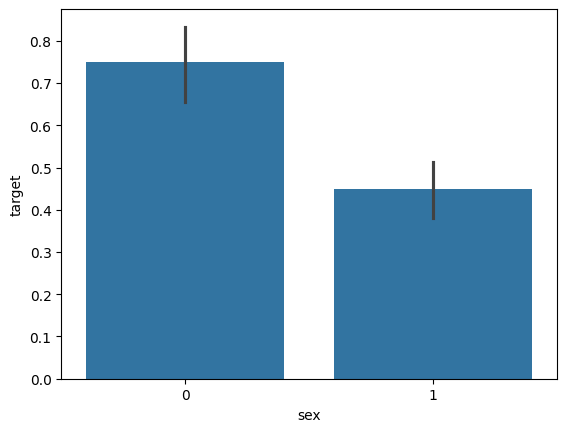

In [18]:
sns.barplot(x=dataset["sex"], y=y)


##### We notice, that females are more likely to have heart problems than males

### Analysing the 'Chest Pain Type' feature

In [19]:
dataset["cp"].unique()

array([3, 2, 1, 0], dtype=int64)

##### As expected, the CP feature has values from 0 to 3

<Axes: xlabel='cp', ylabel='target'>

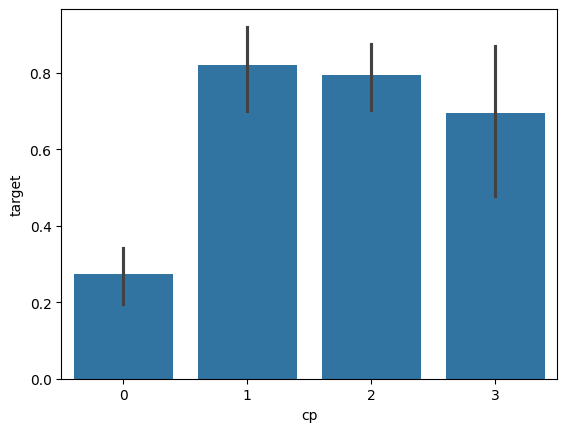

In [20]:
sns.barplot(x=dataset["cp"], y=y)

##### We notice, that chest pain of '0', i.e. the ones with typical angina are much less likely to have heart problems

### Analysing the FBS feature

In [21]:
dataset["fbs"].describe()

count    303.000000
mean       0.148515
std        0.356198
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: fbs, dtype: float64

In [22]:
dataset["fbs"].unique()

array([1, 0], dtype=int64)

<Axes: xlabel='fbs', ylabel='target'>

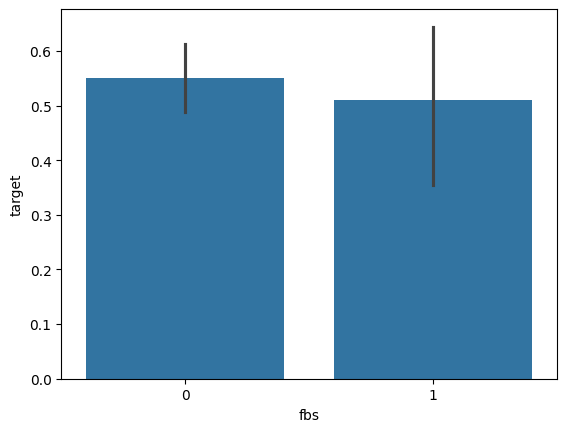

In [23]:
sns.barplot(x=dataset["fbs"],y=y)

##### Nothing extraordinary here

### Analysing the restecg feature

In [24]:
dataset["restecg"].unique()

array([0, 1, 2], dtype=int64)

<Axes: xlabel='restecg', ylabel='target'>

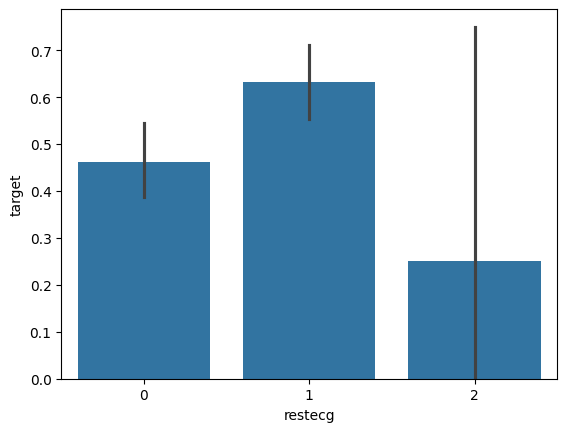

In [25]:
sns.barplot(x=dataset["restecg"],y=y)

##### We realize that people with restecg '1' and '0' are much more likely to have a heart disease than with restecg '2'

### Analysing the 'exang' feature

In [26]:
dataset["exang"].unique()

array([0, 1], dtype=int64)

<Axes: xlabel='exang', ylabel='target'>

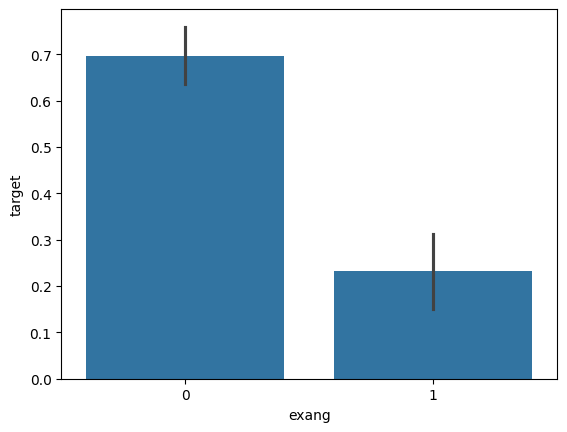

In [27]:
sns.barplot(x=dataset["exang"],y=y)

##### People with exang=1 i.e. Exercise induced angina are much less likely to have heart problems

### Analysing the Slope feature

In [28]:
dataset["slope"].unique()

array([0, 2, 1], dtype=int64)

<Axes: xlabel='slope', ylabel='target'>

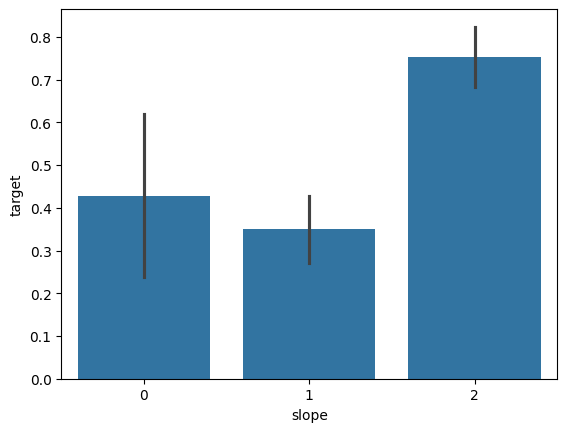

In [29]:
sns.barplot(x=dataset["slope"],y=y)

##### We observe, that Slope '2' causes heart pain much more than Slope '0' and '1'

### Analysing the 'ca' feature

In [30]:
#number of major vessels (0-3) colored by flourosopy

In [31]:
dataset["ca"].unique()

array([0, 2, 1, 3, 4], dtype=int64)

<Axes: xlabel='ca', ylabel='count'>

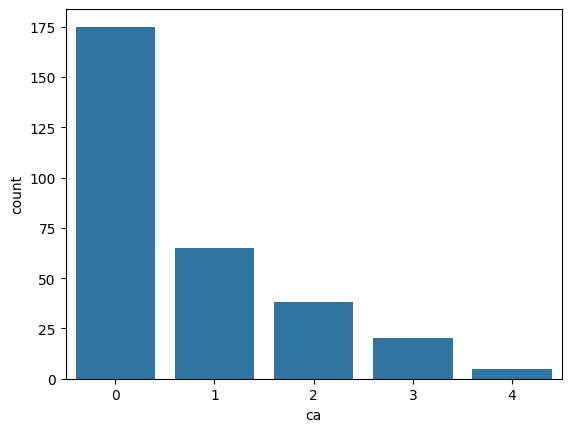

In [32]:
sns.countplot(x=dataset["ca"])

<Axes: xlabel='ca', ylabel='target'>

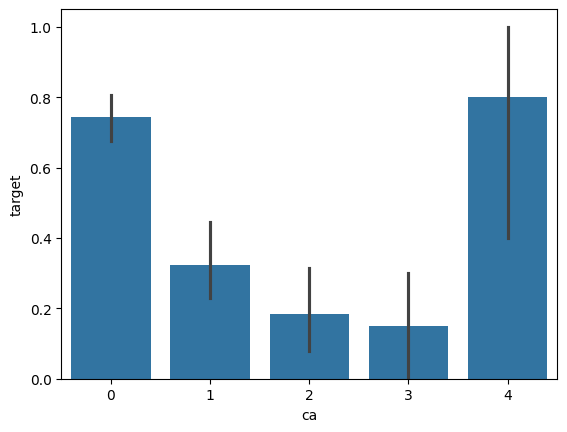

In [33]:
sns.barplot(x=dataset["ca"],y=y)

##### ca=4 has astonishingly large number of heart patients

In [34]:
### Analysing the 'thal' feature

In [35]:
dataset["thal"].unique()

array([1, 2, 3, 0], dtype=int64)

<Axes: xlabel='thal', ylabel='target'>

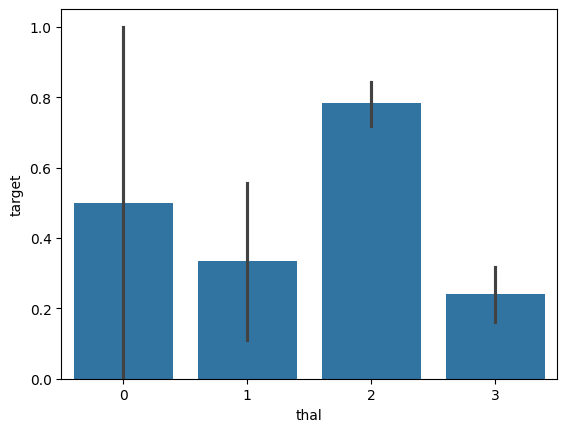

In [36]:
sns.barplot(x=dataset["thal"],y=y)

<Axes: ylabel='Density'>

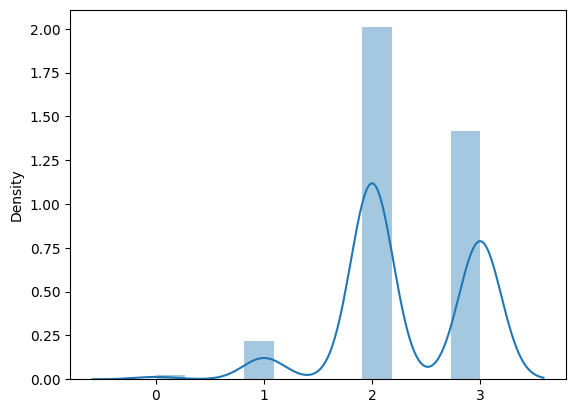

In [37]:
sns.distplot(x=dataset["thal"])

## IV. Train Test split

In [38]:
from sklearn.model_selection import train_test_split

predictors = dataset.drop("target",axis=1)
target = dataset["target"]

X_train,X_test,Y_train,Y_test = train_test_split(predictors,target,test_size=0.20,random_state=0)

In [39]:
X_train.shape

(242, 13)

In [40]:
X_test.shape

(61, 13)

In [41]:
Y_train.shape

(242,)

In [42]:
Y_test.shape

(61,)

## V. Model Fitting

In [43]:
from sklearn.metrics import accuracy_score

### Logistic Regression

In [44]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

lr.fit(X_train,Y_train)

Y_pred_lr = lr.predict(X_test)

In [45]:
Y_pred_lr.shape

(61,)

In [46]:
score_lr = round(accuracy_score(Y_pred_lr,Y_test)*100,2)

print("The accuracy score achieved using Logistic Regression is: "+str(score_lr)+" %")

The accuracy score achieved using Logistic Regression is: 85.25 %


### Naive Bayes

In [47]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train,Y_train)

Y_pred_nb = nb.predict(X_test)

In [48]:
Y_pred_nb.shape

(61,)

In [49]:
score_nb = round(accuracy_score(Y_pred_nb,Y_test)*100,2)

print("The accuracy score achieved using Naive Bayes is: "+str(score_nb)+" %")

The accuracy score achieved using Naive Bayes is: 85.25 %


### SVM

In [50]:
from sklearn import svm

sv = svm.SVC(kernel='linear')

sv.fit(X_train, Y_train)

Y_pred_svm = sv.predict(X_test)

In [51]:
Y_pred_svm.shape

(61,)

In [52]:
score_svm = round(accuracy_score(Y_pred_svm,Y_test)*100,2)

print("The accuracy score achieved using Linear SVM is: "+str(score_svm)+" %")

The accuracy score achieved using Linear SVM is: 81.97 %


### K Nearest Neighbors

In [53]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train,Y_train)
Y_pred_knn=knn.predict(X_test)

In [54]:
Y_pred_knn.shape

(61,)

In [55]:
score_knn = round(accuracy_score(Y_pred_knn,Y_test)*100,2)

print("The accuracy score achieved using KNN is: "+str(score_knn)+" %")

The accuracy score achieved using KNN is: 67.21 %


### Decision Tree

In [56]:
from sklearn.tree import DecisionTreeClassifier

max_accuracy = 0


for x in range(200):
    dt = DecisionTreeClassifier(random_state=x)
    dt.fit(X_train,Y_train)
    Y_pred_dt = dt.predict(X_test)
    current_accuracy = round(accuracy_score(Y_pred_dt,Y_test)*100,2)
    if(current_accuracy>max_accuracy):
        max_accuracy = current_accuracy
        best_x = x
        
#print(max_accuracy)
#print(best_x)


dt = DecisionTreeClassifier(random_state=best_x)
dt.fit(X_train,Y_train)
Y_pred_dt = dt.predict(X_test)

In [57]:
print(Y_pred_dt.shape)

(61,)


In [58]:
score_dt = round(accuracy_score(Y_pred_dt,Y_test)*100,2)

print("The accuracy score achieved using Decision Tree is: "+str(score_dt)+" %")

The accuracy score achieved using Decision Tree is: 81.97 %


### Random Forest

In [59]:
from sklearn.ensemble import RandomForestClassifier
max_accuracy = 0


for x in range(2000):
    rf = RandomForestClassifier(random_state=x)
    rf.fit(X_train,Y_train)
    Y_pred_rf = rf.predict(X_test)
    current_accuracy = round(accuracy_score(Y_pred_rf,Y_test)*100,2)
    if(current_accuracy>max_accuracy):
        max_accuracy = current_accuracy
        best_x = x
        
#print(max_accuracy)
#print(best_x)

rf = RandomForestClassifier(random_state=best_x)
rf.fit(X_train,Y_train)
Y_pred_rf = rf.predict(X_test)

In [60]:
Y_pred_rf.shape

(61,)

In [61]:
score_rf = round(accuracy_score(Y_pred_rf,Y_test)*100,2)

print("The accuracy score achieved using Decision Tree is: "+str(score_rf)+" %")

The accuracy score achieved using Decision Tree is: 90.16 %


### XGBoost

In [62]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
xgb_model.fit(X_train, Y_train)

Y_pred_xgb = xgb_model.predict(X_test)

In [63]:
Y_pred_xgb.shape

(61,)

In [64]:
score_xgb = round(accuracy_score(Y_pred_xgb,Y_test)*100,2)

print("The accuracy score achieved using XGBoost is: "+str(score_xgb)+" %")

The accuracy score achieved using XGBoost is: 83.61 %


### LightGBM Classifier

In [65]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Base model
lgbm = LGBMClassifier(boosting_type='gbdt', objective='binary', random_state=42, verbose=-1)

# Parameter grid for tuning
param_grid = {
    'num_leaves': [15, 31, 63],          # complexity of trees
    'max_depth': [-1, 5, 10],            # -1 = no limit
    'min_child_samples': [5, 10, 20],    # min data in leaf
    'learning_rate': [0.01, 0.05, 0.1],  # smaller = slower but better
    'n_estimators': [100, 200, 500],     # number of boosting rounds
    'subsample': [0.8, 1.0],             # row sampling
    'colsample_bytree': [0.8, 1.0]       # feature sampling
}

# GridSearch with cross-validation
grid = GridSearchCV(
    estimator=lgbm,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,          # 5-fold cross-validation
    verbose=2,
    n_jobs=-1
)

# Fit on training data
grid.fit(X_train, Y_train)

# Best parameters
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

# Evaluate on test set
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print("Test Accuracy:", accuracy_score(Y_test, y_pred))


Fitting 5 folds for each of 972 candidates, totalling 4860 fits
Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 15, 'subsample': 0.8}
Best CV Score: 0.8475340136054422
Test Accuracy: 0.8360655737704918


In [66]:
score_lgbm = round(accuracy_score(Y_test, y_pred) * 100, 2)
print("The accuracy score achieved using LightGBM Classifier is: "+str(score_lgbm)+" %")

The accuracy score achieved using LightGBM Classifier is: 83.61 %


## VI. Output final score

In [67]:
scores = [score_lr,score_nb,score_svm,score_knn,score_dt,score_rf,score_xgb,score_lgbm]
algorithms = ["Logistic Regression","Naive Bayes","Support Vector Machine","K-Nearest Neighbors","Decision Tree","Random Forest","XGBoost","LightGBM "]    

for i in range(len(algorithms)):
    print("The accuracy score achieved using "+algorithms[i]+" is: "+str(scores[i])+" %")

The accuracy score achieved using Logistic Regression is: 85.25 %
The accuracy score achieved using Naive Bayes is: 85.25 %
The accuracy score achieved using Support Vector Machine is: 81.97 %
The accuracy score achieved using K-Nearest Neighbors is: 67.21 %
The accuracy score achieved using Decision Tree is: 81.97 %
The accuracy score achieved using Random Forest is: 90.16 %
The accuracy score achieved using XGBoost is: 83.61 %
The accuracy score achieved using LightGBM  is: 83.61 %


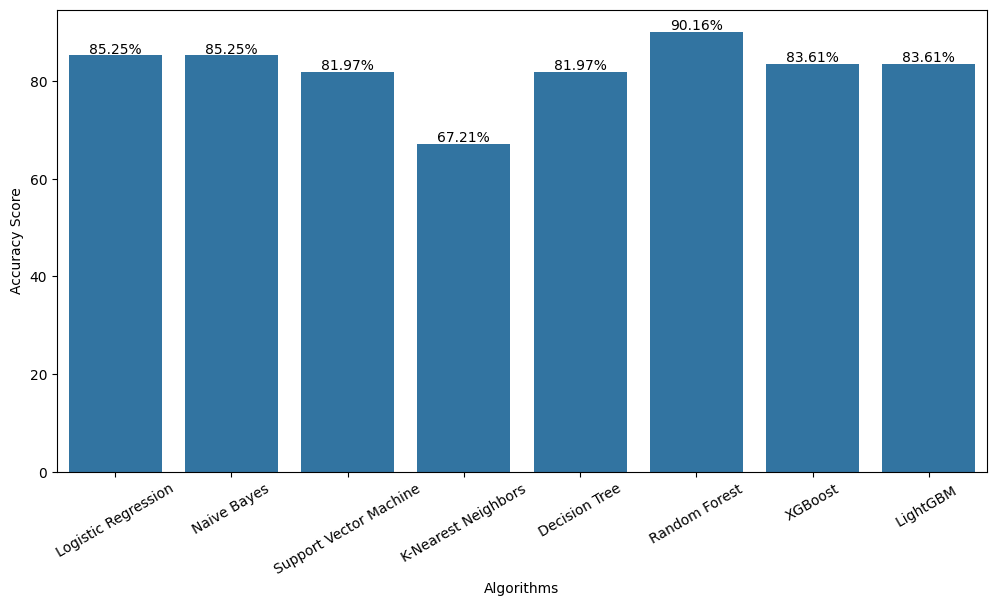

In [68]:
plt.figure(figsize=(12, 6)) 
ax = sns.barplot(x=algorithms, y=scores)

# Add score values on top of each bar
for i, score in enumerate(scores):
    ax.text(i, score + 0.5, f"{score:.2f}%", ha='center')

plt.xlabel("Algorithms")
plt.ylabel("Accuracy Score")
plt.xticks(rotation=30)  # rotate x-axis labels for readability
plt.show()

In [69]:
import numpy as np

# Input data with 13 features (same as training dataset)
# Format: [age, sex, cp, trestbps, chol, fbs, restecg, thalach,
#          exang, oldpeak, slope, ca, thal]
input_data = np.array([[63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 2]])

# Predict
prediction = rf.predict(input_data)[0]

if prediction == 1:
    print("Patient likely has heart disease")
else:
    print("Patient unlikely to have heart disease")


Patient likely has heart disease


In [70]:
import numpy as np
input_data = np.array([[63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 2]])
prediction = rf.predict(input_data)[0]
proba = rf.predict_proba(input_data)[0]   # gives [prob_no_disease, prob_disease]
print(f"Probability of No Heart Disease: {proba[0]*100:.2f}%")
print(f"Probability of Heart Disease: {proba[1]*100:.2f}%")
# Final decision
if prediction == 1:
    print("Patient likely has heart disease")
else:
    print("Patient unlikely to have heart disease")


Probability of No Heart Disease: 16.00%
Probability of Heart Disease: 84.00%
Patient likely has heart disease


In [71]:
import numpy as np
import pandas as pd
input_data = np.array([
    [63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 2],  # Patient 1
    [45, 0, 2, 120, 240, 0, 1, 160, 0, 1.0, 2, 0, 3],  # Patient 2
    [54, 1, 1, 130, 250, 0, 1, 140, 1, 1.5, 1, 0, 2],  # Patient 3
    [38, 0, 0, 110, 190, 0, 0, 170, 0, 0.0, 2, 0, 2],  # Patient 4
    [60, 1, 2, 140, 260, 1, 1, 120, 1, 3.5, 0, 1, 3]   # Patient 5
])

# Predict for all patients
predictions = rf.predict(input_data)
probabilities = rf.predict_proba(input_data)

# Convert results into a DataFrame for easy display
results = []
for i, (pred, proba) in enumerate(zip(predictions, probabilities), start=1):
    results.append({
        "Patient": i,
        "No Heart Disease %": round(proba[0]*100, 2),
        "Heart Disease %": round(proba[1]*100, 2),
        "Prediction": " Heart Disease" if pred == 1 else " No Heart Disease"
    })

results_df = pd.DataFrame(results)
print(results_df)


   Patient  No Heart Disease %  Heart Disease %         Prediction
0        1                16.0             84.0      Heart Disease
1        2                17.0             83.0      Heart Disease
2        3                41.0             59.0      Heart Disease
3        4                18.0             82.0      Heart Disease
4        5                81.0             19.0   No Heart Disease


### Voting Classifier for SVM, XGBoost and LightGBM 

In [72]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
import joblib
import numpy as np

# Make sure SVC supports predict_proba -> probability=True
svm_clf = SVC(kernel='linear', probability=True, random_state=42)

# LightGBM and XGBoost (set random_state for reproducibility)
lgb_clf = LGBMClassifier(random_state=42)
# For recent xgboost versions, avoid label encoder warning and set eval_metric
xgb_clf = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# Create the soft voting classifier
voting_clf = VotingClassifier(
    estimators=[('svm', svm_clf), ('lgb', lgb_clf), ('xgb', xgb_clf)],
    voting='soft',  # soft uses predicted probabilities
    n_jobs=-1
)

# Fit the voting classifier on training data
voting_clf.fit(X_train, Y_train)

# Predict and probability on test set
vc_pred = voting_clf.predict(X_test)
vc_proba = voting_clf.predict_proba(X_test)  # shape (n_samples, 2) in binary case


### Evaluation for SVM

In [73]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Calculate metrics
svm_accuracy = accuracy_score(Y_test, Y_pred_svm)
svm_precision = precision_score(Y_test, Y_pred_svm)
svm_recall = recall_score(Y_test, Y_pred_svm)
svm_f1_score = f1_score(Y_test, Y_pred_svm)

# Specificity = TN / (TN + FP)
cm = confusion_matrix(Y_test, Y_pred_svm)
tn, fp, fn, tp = cm.ravel()
svm_specificity = tn / (tn + fp)

# Print results
print('SVM Evaluation Metrics:')
print("Accuracy : {:.2f}%".format(svm_accuracy * 100))
print(f'Precision: {svm_precision:.3f}')
print(f'Recall: {svm_recall:.3f}')
print(f'F1-score: {svm_f1_score:.3f}')
print(f'Specificity: {svm_specificity:.3f}\n')


SVM Evaluation Metrics:
Accuracy : 81.97%
Precision: 0.811
Recall: 0.882
F1-score: 0.845
Specificity: 0.741



### Evaluation for XGBoost

In [74]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# XGBoost evaluation
xgb_accuracy  = accuracy_score(Y_test, Y_pred_xgb)
xgb_precision = precision_score(Y_test, Y_pred_xgb)
xgb_recall    = recall_score(Y_test, Y_pred_xgb)
xgb_f1_score  = f1_score(Y_test, Y_pred_xgb)

cm_xgb = confusion_matrix(Y_test, Y_pred_xgb)
tn, fp, fn, tp = cm_xgb.ravel()
xgb_specificity = tn / (tn + fp)

print("\nXGBoost - Heart Disease:")
print("Accuracy : {:.2f}%".format(xgb_accuracy * 100))
print("Precision: {:.2f}".format(xgb_precision))
print("Recall   : {:.2f}".format(xgb_recall))
print("F1-Score : {:.2f}".format(xgb_f1_score))
print("Specificity: {:.2f}".format(xgb_specificity))



XGBoost - Heart Disease:
Accuracy : 83.61%
Precision: 0.85
Recall   : 0.85
F1-Score : 0.85
Specificity: 0.81


### Evaluation for LightGBM

In [75]:
# LightGBM evaluation
lgb_accuracy  = accuracy_score(Y_test, y_pred)
lgb_precision = precision_score(Y_test, y_pred)
lgb_recall    = recall_score(Y_test, y_pred)
lgb_f1_score  = f1_score(Y_test, y_pred)

cm_lgb = confusion_matrix(Y_test, y_pred)
tn, fp, fn, tp = cm_lgb.ravel()
lgb_specificity = tn / (tn + fp)

print("\nLightGBM - Heart Disease:")
print("Accuracy : {:.2f}%".format(lgb_accuracy * 100))
print("Precision: {:.2f}".format(lgb_precision))
print("Recall   : {:.2f}".format(lgb_recall))
print("F1-Score : {:.2f}".format(lgb_f1_score))
print("Specificity: {:.2f}".format(lgb_specificity))



LightGBM - Heart Disease:
Accuracy : 83.61%
Precision: 0.82
Recall   : 0.91
F1-Score : 0.86
Specificity: 0.74


### Voting Classifier Evaluation for SVM, XGBoost and LightGBM 

In [76]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Voting evaluation
voting_accuracy  = accuracy_score(Y_test, vc_pred)
voting_precision = precision_score(Y_test, vc_pred)
voting_recall    = recall_score(Y_test, vc_pred)
voting_f1_score  = f1_score(Y_test, vc_pred)

cm_voting = confusion_matrix(Y_test, vc_pred)
tn, fp, fn, tp = cm_voting.ravel()
voting_specificity = tn / (tn + fp)

print("\nVoting Classifier - Heart Disease:")
print("Accuracy : {:.2f}%".format(voting_accuracy * 100))
print("Precision: {:.2f}".format(voting_precision))
print("Recall   : {:.2f}".format(voting_recall))
print("F1-Score : {:.2f}".format(voting_f1_score))
print("Specificity: {:.2f}".format(voting_specificity))



Voting Classifier - Heart Disease:
Accuracy : 85.25%
Precision: 0.86
Recall   : 0.88
F1-Score : 0.87
Specificity: 0.81


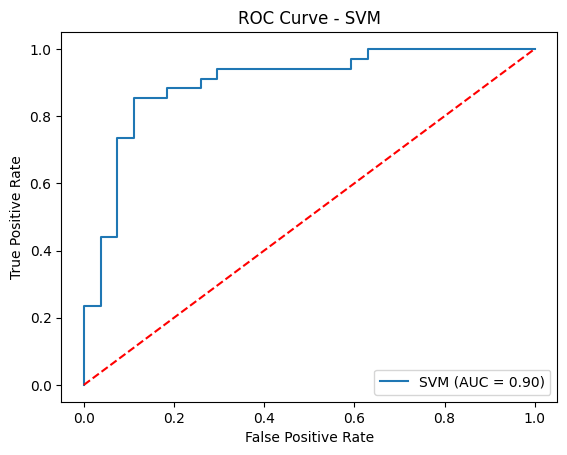

In [77]:
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Train SVM with probability enabled
svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train, Y_train)

# Predict probabilities
svm_fpr, svm_tpr, svm_thresholds = roc_curve(Y_test, svm_model.predict_proba(X_test)[:,1])
svm_roc_auc = auc(svm_fpr, svm_tpr)

# Plot ROC
plt.figure()
plt.plot(svm_fpr, svm_tpr, label='SVM (AUC = %0.2f)' % svm_roc_auc)
plt.plot([0,1],[0,1],'r--')  # diagonal baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend(loc="lower right")
plt.show()


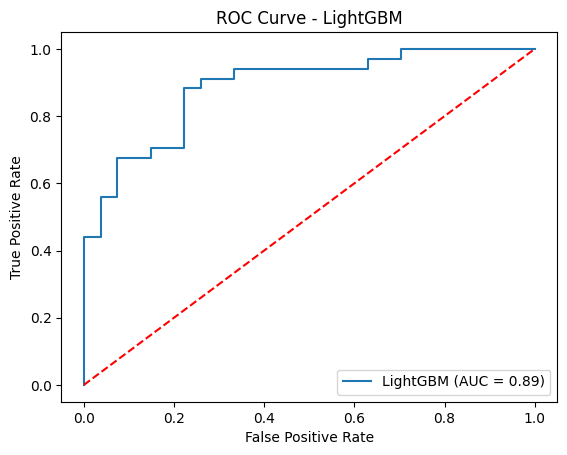

In [78]:
# For LightGBM ROC
lgb_probs = best_model.predict_proba(X_test)[:,1]   # probability for class 1
lgb_fpr, lgb_tpr, lgb_thresholds = roc_curve(Y_test, lgb_probs)
lgb_roc_auc = auc(lgb_fpr, lgb_tpr)

plt.plot(lgb_fpr, lgb_tpr, label='LightGBM (AUC = %0.2f)' % lgb_roc_auc)
plt.plot([0,1],[0,1],'r--')  # diagonal baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - LightGBM")
plt.legend(loc="lower right")
plt.show()


### Voting Classifier for Random Forest, Logistic Regression and Naive Bayes


Voting Classifier (RF + LR + NB):
Accuracy : 83.61%
              precision    recall  f1-score   support

           0       0.84      0.78      0.81        27
           1       0.83      0.88      0.86        34

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



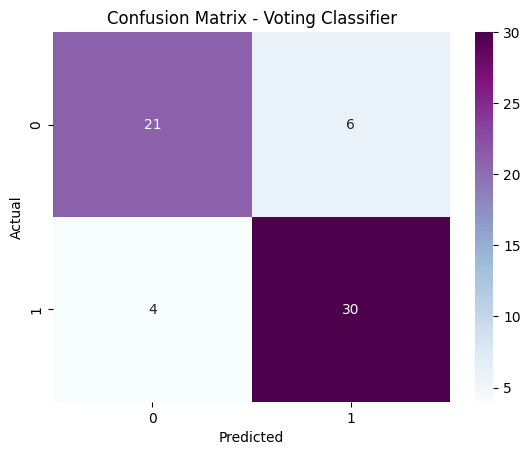

In [79]:
# --- Voting Classifier (Random Forest + Logistic Regression + Naive Bayes) ---

from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- Base Models ---
rf = RandomForestClassifier(random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=42)
nb = GaussianNB()

# --- Voting Classifier (Soft Voting gives better probability-based results) ---
voting_clf = VotingClassifier(
    estimators=[('rf', rf), ('lr', lr), ('nb', nb)],
    voting='soft'   # soft = based on predicted probabilities
)

# --- Fit the model ---
voting_clf.fit(X_train, Y_train)

# --- Predictions ---
y_pred_voting = voting_clf.predict(X_test)

# --- Evaluation ---
print("\nVoting Classifier (RF + LR + NB):")
print("Accuracy : {:.2f}%".format(accuracy_score(Y_test, y_pred_voting) * 100))
print(classification_report(Y_test, y_pred_voting))

# Confusion Matrix
conf_matrix = confusion_matrix(Y_test, y_pred_voting)
sns.heatmap(conf_matrix, annot=True, cmap="BuPu", fmt="d")
plt.title("Confusion Matrix - Voting Classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [80]:
rf = RandomForestClassifier(random_state=42)

# Fit BEFORE saving
rf.fit(X_train, Y_train)

# Evaluate
Y_pred_rf = rf.predict(X_test)
score_rf = accuracy_score(Y_test, Y_pred_rf)
print("Random Forest Accuracy:", score_rf)

Random Forest Accuracy: 0.8524590163934426


In [81]:
# --- Train Random Forest Model ---
from sklearn.ensemble import RandomForestClassifier
import pickle

# Best random_state found earlier (replace best_x with your chosen one)
rf = RandomForestClassifier(random_state=42)  
rf.fit(X_train, Y_train)

# --- Save the trained model ---
with open("heart_model.pkl", "wb") as file:
    pickle.dump(rf, file)

print("✅ Model saved successfully as heart_model.pkl")


✅ Model saved successfully as heart_model.pkl


In [82]:
import shap
import matplotlib.pyplot as plt
import numpy as np

In [83]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    shap.initjs()
except Exception:
    pass

# build explainer
background = X_train.copy()
try:
    explainer = shap.TreeExplainer(rf, data=background)
except Exception:
    explainer = shap.Explainer(rf, background)

# compute raw shap values
try:
    raw = explainer.shap_values(X_test)
except Exception:
    shap_explanation = explainer(X_test)
    raw = shap_explanation.values

# --- auto-slice to correct (n_samples, n_features) shape ---
if isinstance(raw, list):
    shap_vals = raw[1]  # positive class
elif isinstance(raw, np.ndarray):
    if raw.ndim == 3:
        if raw.shape[1] == X_test.shape[1] and raw.shape[2] == 2:
            # (n_samples, n_features, n_classes)
            shap_vals = raw[:, :, 1]    # positive class
        elif raw.shape[1] == 2 and raw.shape[2] == X_test.shape[1]:
            # (n_samples, n_classes, n_features)
            shap_vals = raw[:, 1, :]
        elif raw.shape[0] == 2 and raw.shape[2] == X_test.shape[1]:
            # (n_classes, n_samples, n_features)
            shap_vals = raw[1, :, :]
        else:
            raise ValueError(f"Unexpected SHAP array shape {raw.shape}")
    else:  # already 2-D
        shap_vals = raw
else:
    raise ValueError(f"Unknown SHAP output type: {type(raw)}")

print("X_test shape:", X_test.shape, "SHAP values shape:", shap_vals.shape)


X_test shape: (61, 13) SHAP values shape: (61, 13)


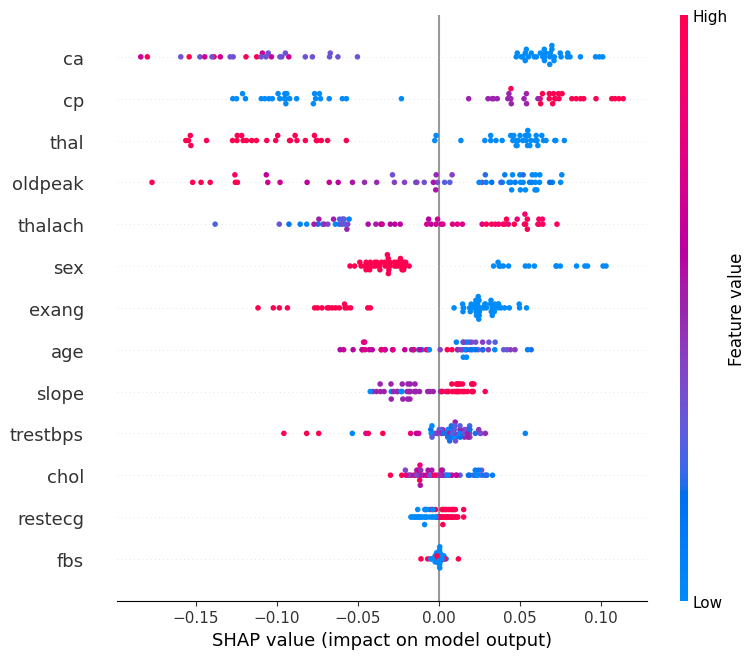

In [84]:
# --- global explanations ---
plt.figure(figsize=(10,7))
shap.summary_plot(shap_vals, X_test, feature_names=X_test.columns)


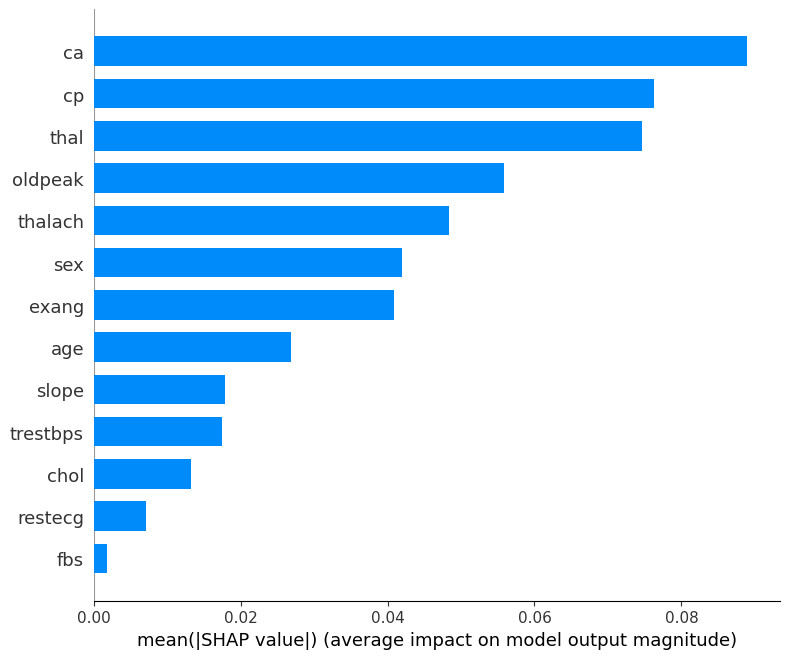

In [85]:
plt.figure(figsize=(10,6))
shap.summary_plot(shap_vals, X_test, plot_type="bar", feature_names=X_test.columns)

Top feature by mean |SHAP|: ca


<Figure size 800x600 with 0 Axes>

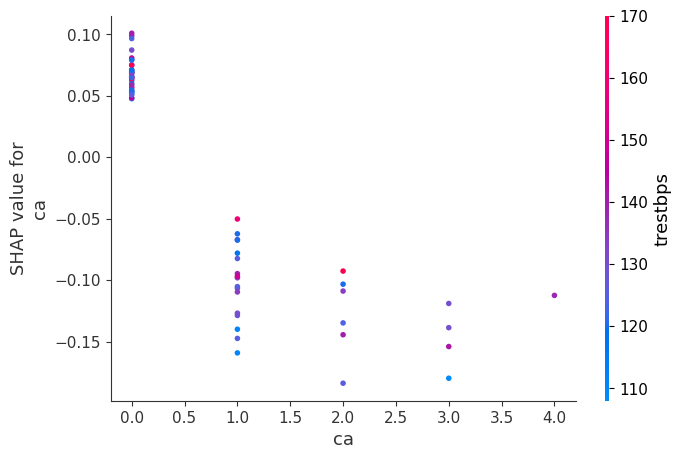

In [86]:
# --- dependence plot for top feature ---
mean_abs_shap = np.abs(shap_vals).mean(axis=0)
top_idx = np.argmax(mean_abs_shap)
top_feature = X_test.columns[top_idx]
print("Top feature by mean |SHAP|:", top_feature)

plt.figure(figsize=(8,6))
shap.dependence_plot(top_feature, shap_vals, X_test)

In [87]:
# --- local explanation (force plot) for one sample ---
sample_idx = 0
expected_value = getattr(explainer, "expected_value", None)
try:
    if expected_value is not None:
        if isinstance(expected_value, (list, tuple, np.ndarray)) and len(np.shape(expected_value)) > 0:
            ev = expected_value[1] if len(expected_value) > 1 else expected_value[0]
        else:
            ev = expected_value
        display(shap.force_plot(ev, shap_vals[sample_idx,:], X_test.iloc[sample_idx,:]))
    else:
        display(shap.plots.force(shap_explanation[sample_idx]))
except Exception as e:
    print("Force plot not shown inline:", e)
    contribs = pd.Series(shap_vals[sample_idx,:], index=X_test.columns).sort_values(key=lambda x: np.abs(x), ascending=False)
    print("\nTop feature contributions for test sample", sample_idx)
    print(contribs.head(10))


In [88]:
# --- local explanation (force plot) for 6 sample ---
sample_idx = 6
expected_value = getattr(explainer, "expected_value", None)
try:
    if expected_value is not None:
        if isinstance(expected_value, (list, tuple, np.ndarray)) and len(np.shape(expected_value)) > 0:
            ev = expected_value[1] if len(expected_value) > 1 else expected_value[0]
        else:
            ev = expected_value
        display(shap.force_plot(ev, shap_vals[sample_idx,:], X_test.iloc[sample_idx,:]))
    else:
        display(shap.plots.force(shap_explanation[sample_idx]))
except Exception as e:
    print("Force plot not shown inline:", e)
    contribs = pd.Series(shap_vals[sample_idx,:], index=X_test.columns).sort_values(key=lambda x: np.abs(x), ascending=False)
    print("\nTop feature contributions for test sample", sample_idx)
    print(contribs.head(10))


In [89]:
# --- local explanation (force plot) for 15 sample ---
sample_idx = 15
expected_value = getattr(explainer, "expected_value", None)
try:
    if expected_value is not None:
        if isinstance(expected_value, (list, tuple, np.ndarray)) and len(np.shape(expected_value)) > 0:
            ev = expected_value[1] if len(expected_value) > 1 else expected_value[0]
        else:
            ev = expected_value
        display(shap.force_plot(ev, shap_vals[sample_idx,:], X_test.iloc[sample_idx,:]))
    else:
        display(shap.plots.force(shap_explanation[sample_idx]))
except Exception as e:
    print("Force plot not shown inline:", e)
    contribs = pd.Series(shap_vals[sample_idx,:], index=X_test.columns).sort_values(key=lambda x: np.abs(x), ascending=False)
    print("\nTop feature contributions for test sample", sample_idx)
    print(contribs.head(10))


In [98]:
import shap
from IPython.display import display

shap.initjs()

# for binary classifier, select positive class shap values
shap_values_pos = shap_values[:, :, 1]  # class 1 (positive)

print(shap_values_pos.shape, X_test.shape)

expected_value = explainer.expected_value[1]  # base value for positive class

# show force plot for first 100 samples
display(
    shap.force_plot(
        expected_value,                  # base value
        shap_values_pos[:100, :],        # shap values for positive class
        X_test.iloc[:100, :]             # corresponding feature values
    )
)


(61, 13) (61, 13)


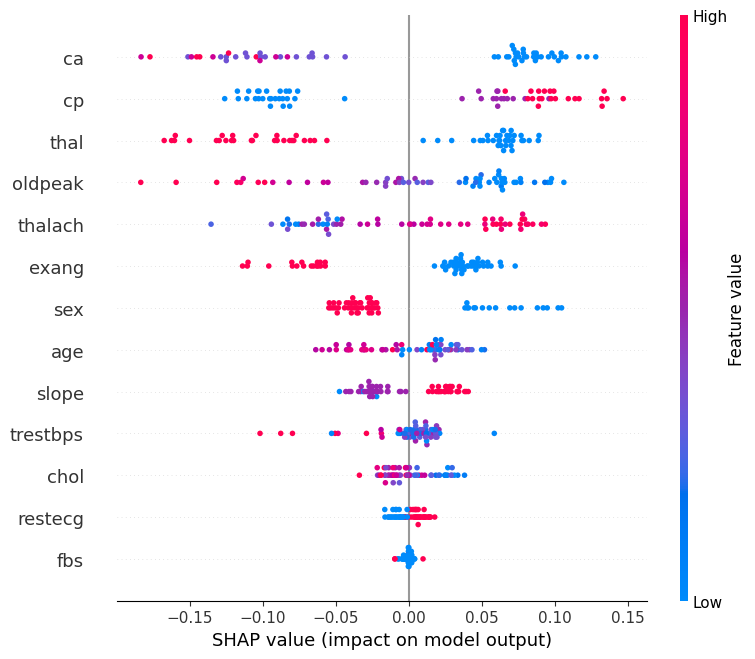

In [100]:
import shap

# For binary classification: pick positive class (1)
shap_values_pos = shap_values[:, :, 1]  # take SHAP values for positive class

# Initialize JS visualization
shap.initjs()

# Summary plot for global feature importance
shap.summary_plot(shap_values_pos, X_test)
